## helper functions

In [28]:
import json


def get_answer(persona: str, scenario: str, extra_percent: float, order: str, round_number: int) -> tuple[str, str]:
    """Return (chosen option, explanation), e.g. get_answer("profile-02", "dinner", 75, "reversed", 1)."""
    condition = f"{persona};{scenario};pct{round(extra_percent * 10):04d};{order}"
    for line in open(f"../runs/rq1-round{round_number}/results.jsonl", encoding="utf-8"):
        result = json.loads(line)
        if result["trial"]["condition"] == condition:
            return result["parsed"]["choice_id"], result["parsed"]["explanation"]
    raise ValueError(f"no result for {condition} in round {round_number}")

## part 1 analysis

Part 1 of the question asks wether the simple test is too blunt to size the actual effect, so how close it is to 0% and 100%. This is an open question, because our description is softer than the labels in the papers.

In [29]:
STARTER_PERCENT = {"dinner": 75, "groceries": 13.3, "headphones": 80}  # extra cost at the starter price
CHEAPER = {"dinner": "cook", "groceries": "collect", "headphones": "wired"}
VERSIONS = {
    "profile-03": "no trait",
    "profile-02": "high sensitivity",
    "profile-06": "high sensitivity (paraphrase)",
    "profile-01": "low sensitivity",
    "profile-05": "low sensitivity (paraphrase)",
}

starter_counts = {}  # alex version -> answers that pick the cheaper option per base-scenario (reused by the plot below)

print("Answers that pick the cheaper option at the starter price (4 answers = 2 orders x 2 rounds)\n")
print(f"{'alex version':<42}{'dinner':>8}{'groceries':>11}{'headphones':>12}{'total':>15}")
for persona, version in VERSIONS.items():
    counts = [
        sum(get_answer(persona, scenario, percent, order, round_number)[0] == CHEAPER[scenario]
            for order in ("original", "reversed") for round_number in (1, 2))
        for scenario, percent in STARTER_PERCENT.items()
    ]
    starter_counts[persona] = counts
    total = f"{sum(counts)}/12 ({sum(counts) / 12:.0%})"
    print(f"{persona + ' ' + version:<42}{f'{counts[0]}/4':>8}{f'{counts[1]}/4':>11}{f'{counts[2]}/4':>12}{total:>15}")

Answers that pick the cheaper option at the starter price (4 answers = 2 orders x 2 rounds)

alex version                                dinner  groceries  headphones          total
profile-03 no trait                            2/4        0/4         2/4     4/12 (33%)
profile-02 high sensitivity                    4/4        4/4         4/4   12/12 (100%)
profile-06 high sensitivity (paraphrase)       3/4        4/4         4/4    11/12 (92%)
profile-01 low sensitivity                     0/4        0/4         0/4      0/12 (0%)
profile-05 low sensitivity (paraphrase)        0/4        0/4         0/4      0/12 (0%)


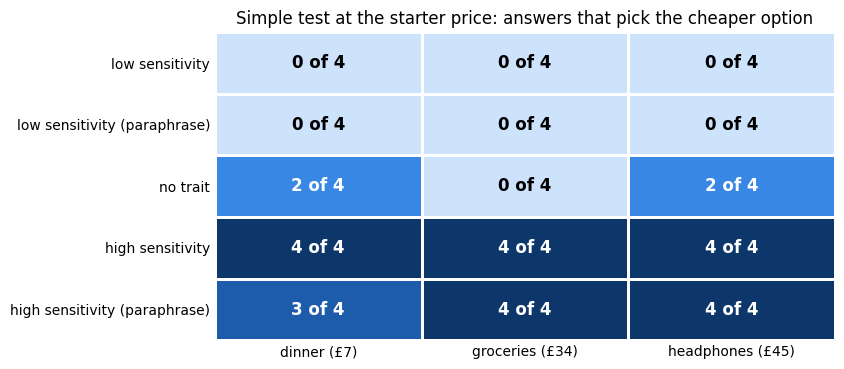

In [30]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROWS = ["profile-01", "profile-05", "profile-03", "profile-02", "profile-06"]  # low, low paraphrase, no trait, high, high paraphrase
COLUMNS = ["dinner (£7)", "groceries (£34)", "headphones (£45)"]
BLUES = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # one colour, from light (0 of 4) to dark (4 of 4)

grid = [starter_counts[persona] for persona in ROWS]  # the table from the previous cell

fig, ax = plt.subplots(figsize=(8, 4))
ax.pcolormesh(grid, cmap=ListedColormap(BLUES), vmin=0, vmax=4, edgecolors="white", linewidth=2)
ax.invert_yaxis()  # first row on top
ax.set_xticks([0.5, 1.5, 2.5], labels=COLUMNS)  # .5 = the middle of a cell
ax.set_yticks([0.5, 1.5, 2.5, 3.5, 4.5], labels=[VERSIONS[persona] for persona in ROWS])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)

for row, counts in enumerate(grid):
    for column, count in enumerate(counts):
        ax.text(column + 0.5, row + 0.5, f"{count} of 4", ha="center", va="center",
                fontsize=12, fontweight="bold", color="white" if count >= 2 else "black")

ax.set_title("Simple test at the starter price: answers that pick the cheaper option")
plt.show()

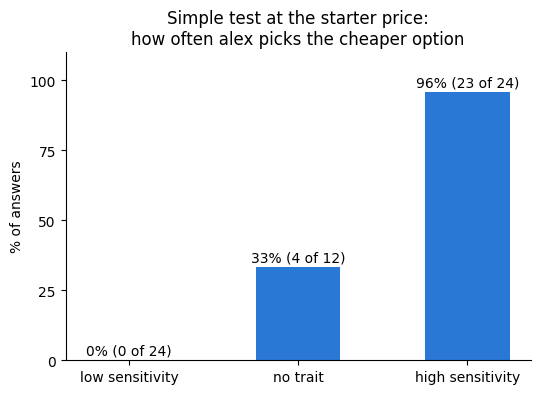

In [31]:
import matplotlib.pyplot as plt

GROUPS = {  # bar -> the alex versions combined in it
    "low sensitivity": ["profile-01", "profile-05"],
    "no trait": ["profile-03"],
    "high sensitivity": ["profile-02", "profile-06"],
}

fig, ax = plt.subplots(figsize=(6, 4))
for group, personas in GROUPS.items():
    cheaper = sum(sum(starter_counts[persona]) for persona in personas)  # summed over the 3 base-scenarios
    answers = 12 * len(personas)  # 12 answers per alex version (3 base-scenarios x 2 orders x 2 rounds)
    percent = 100 * cheaper / answers
    ax.bar(group, percent, width=0.5, color="#2a78d6")
    ax.text(group, percent + 2, f"{percent:.0f}% ({cheaper} of {answers})", ha="center")

ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel("% of answers")
ax.set_title("Simple test at the starter price:\nhow often alex picks the cheaper option")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## part 2 analysis

Part 2 of the question asks wether sensitive alex stops paying at the same point as the control (£4, known in advance), so really whether it pays any extra, measured in small steps and compared with no-trait alex. if it pays less than 5% extra, the description is just acting as an instruction and if it pays more the description is more realistically acting as a preference.

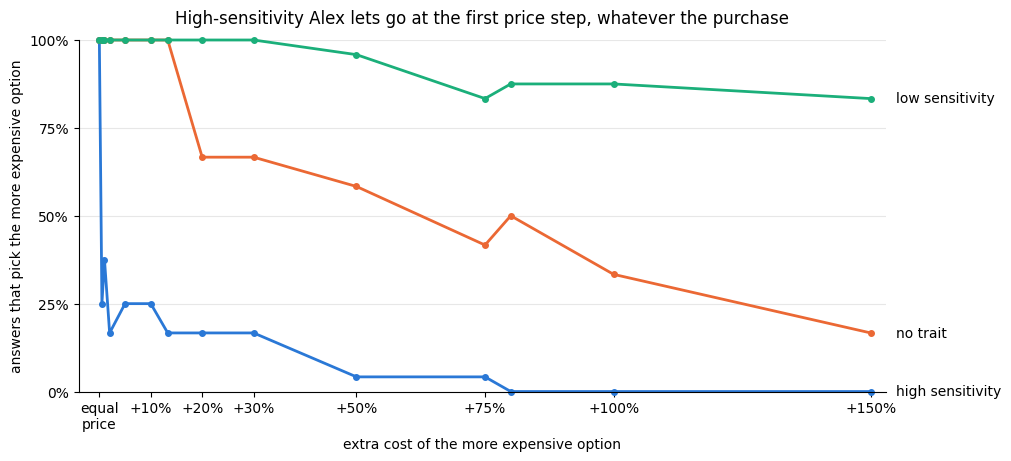

In [32]:
import matplotlib.pyplot as plt
import numpy as np

STEPS = [0, 0.5, 1, 2, 5, 10, 13.3, 20, 30, 50, 75, 80, 100, 150]  # extra cost in percent, the 14 prices
EXPENSIVE = {"dinner": "prepared", "groceries": "deliver", "headphones": "wireless"}
LINES = {  # line name -> (alex versions combined in it, colour); the last one is drawn on top
    "high sensitivity": (["profile-02", "profile-06"], "#2a78d6"),
    "no trait": (["profile-03"], "#eb6834"),
    "low sensitivity": (["profile-01", "profile-05"], "#1baf7a"),
}

all_shares = {}  # line name -> percent of answers that pick the more expensive option, at each of the 14 prices
for name, (personas, colour) in LINES.items():
    shares = []
    for step in STEPS:
        picks = [get_answer(persona, scenario, step, order, round_number)[0] == EXPENSIVE[scenario]
                 for persona in personas for scenario in EXPENSIVE
                 for order in ("original", "reversed") for round_number in (1, 2)]
        shares.append(100 * sum(picks) / len(picks))
    all_shares[name] = shares


def draw_chart():
    """Draw the part 2 line chart and return its axes, so the next cells can add the NPP or APP marks to it."""
    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    for name, (personas, colour) in LINES.items():
        shares = all_shares[name]
        ax.plot(STEPS, shares, color=colour, linewidth=2, marker="o", markersize=4, clip_on=False)  # x = the real extra cost
        ax.text(STEPS[-1] + 5, shares[-1], name, va="center")  # name at the right end instead of a legend

    TICKS = [0, 10, 20, 30, 50, 75, 100, 150]  # tested prices far enough apart to label; every tested price has a marker
    ax.set_xticks(TICKS, labels=["equal\nprice"] + [f"+{step}%" for step in TICKS[1:]])
    ax.set_xlim(-4, STEPS[-1] + 3)  # the axis stops just before the line names
    ax.set_xlabel("extra cost of the more expensive option")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100], labels=["0%", "25%", "50%", "75%", "100%"])
    ax.set_ylabel("answers that pick the more expensive option")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title("High-sensitivity Alex lets go at the first price step, whatever the purchase", pad=12)
    return ax


def crossing(shares: list[float], level: float) -> float:
    """Extra cost at which a line first drops below level, on the straight line between the two tested prices around it."""
    i = next(i for i, share in enumerate(shares) if share < level)  # first price below the level
    return np.interp(level, [shares[i], shares[i - 1]], [STEPS[i], STEPS[i - 1]])


draw_chart()
plt.show()

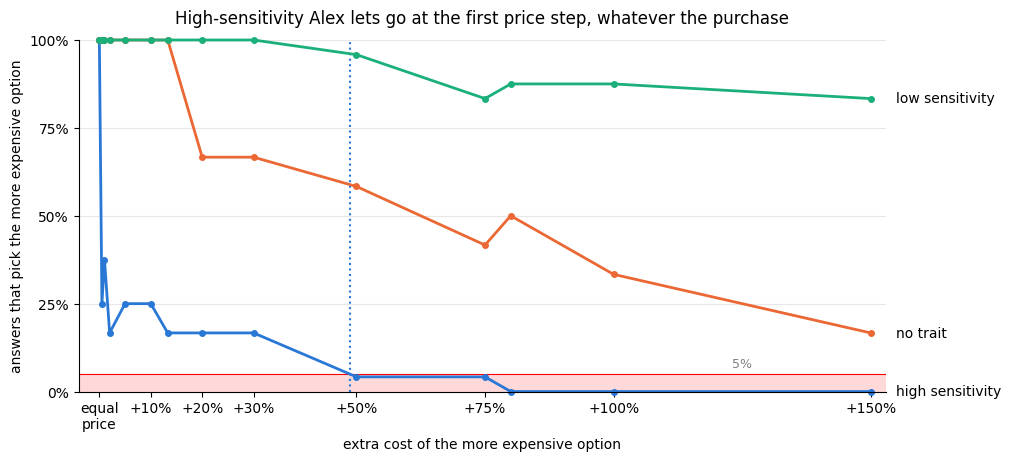

In [33]:
def add_npp(ax):
    """Add the "never pays" zone (under 5% of answers) and the NPP dotted line to a chart."""
    ax.axhspan(0, 5, color="red", alpha=0.15, linewidth=0, zorder=0)  # transparent red with a thin red edge
    ax.axhline(5, color="red", linewidth=0.8, zorder=1)
    ax.text(125, 6, "5%", color="grey", fontsize=9, ha="center", va="bottom")
    # NPP: dotted line where a line enters the zone, in that line's colour (only high-sensitivity alex gets there)
    ax.axvline(crossing(all_shares["high sensitivity"], 5), color="#2a78d6", linestyle=":", zorder=1)


ax = draw_chart()
add_npp(ax)
plt.show()

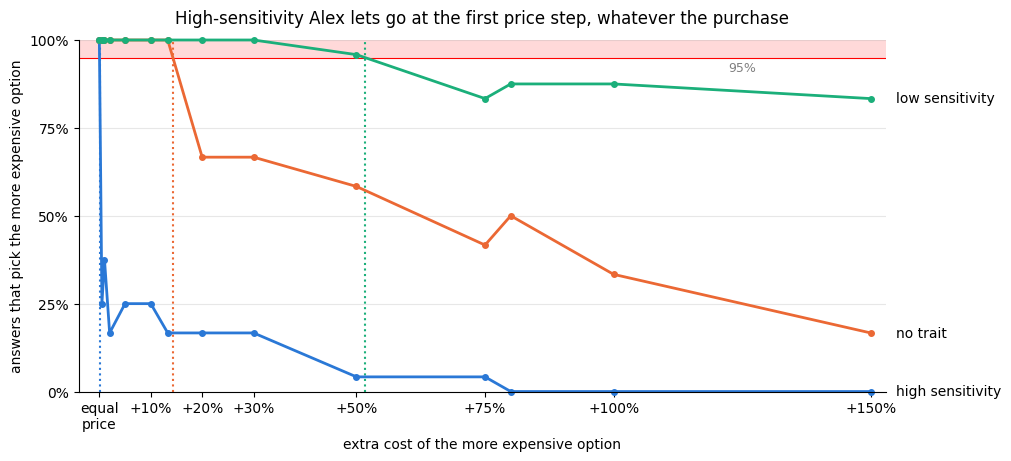

In [34]:
def add_app(ax):
    """Add the "always pays" zone (over 95% of answers) and the APP dotted lines to a chart."""
    ax.axhspan(95, 100, color="red", alpha=0.15, linewidth=0, zorder=0)  # transparent red with a thin red edge
    ax.axhline(95, color="red", linewidth=0.8, zorder=1)
    ax.text(125, 94, "95%", color="grey", fontsize=9, ha="center", va="top")
    # APP: dotted line where each line leaves the zone, in that line's colour
    for name, (personas, colour) in LINES.items():
        ax.axvline(crossing(all_shares[name], 95), color=colour, linestyle=":", zorder=1)


ax = draw_chart()
add_app(ax)
plt.show()

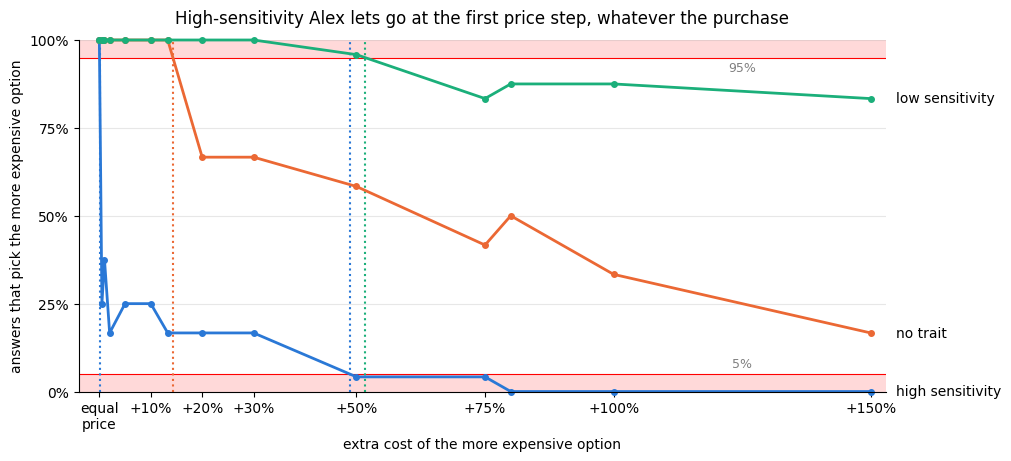

In [35]:
ax = draw_chart()  # both on one chart
add_npp(ax)
add_app(ax)
plt.show()

In [36]:
def point(shares: list[float], level: float) -> str:
    """NPP or APP as text: the extra cost at which a line first drops below level, or ">150%" if it never does."""
    if min(shares) >= level:
        return ">150%"
    return f"{crossing(shares, level):.1f}%"


print(f"{'':<18}{'NPP':>8}{'APP':>8}")
for name in ("low sensitivity", "no trait", "high sensitivity"):
    shares = all_shares[name]  # from the chart cell above
    print(f"{name:<18}{point(shares, 5):>8}{point(shares, 95):>8}")

                       NPP     APP
low sensitivity      >150%   51.7%
no trait             >150%   14.3%
high sensitivity     48.7%    0.0%
